# Part 4 — Interpretation: what do the models look at, and do they take shortcuts?

Hypotheses H4.1–H4.5 were committed before this notebook was run (`HYPOTHESES.md`, Block 4).
Models: ResNet-18 SGD (best CNN), own scratch ViT (best ViT / overall), pretrained ViT-S (contrast),
frozen DINOv2-S (SSL, attention rollout of the pretrained encoder). Every map and every control uses
the **fold model for which the sample was held out**, so nothing is evaluated on training samples.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import timm
import torch

from soilgs import paths
from soilgs.baselines import ridge_tile_oof, tile_feature_table
from soilgs.experiment import fold_scores
from soilgs.interpret import (load_trained, sample_curves, emd_of, photo_map, grayscale, shuffle_patches,
                              mean_colour_only, centre_tiles, border_tiles)
from soilgs.metric import COLS, emd
from soilgs.train import Data, get_device

plt.rcParams.update({"figure.dpi": 110})
device = get_device()
data = Data.load()
labels, folds, photos = data.labels, data.folds, data.photos
lab = labels.set_index("sample_id")
fold_of = folds.set_index("sample_id").fold
group = pd.cut(lab["2"], [-1, 60, 90, 101], labels=["gravelly", "mixed", "fine"])
MODELS = {"ResNet-18 SGD": "final_r18_sgd", "scratch ViT": "final_tinyvit_scratch", "ViT-S (IN-21k)": "final_vits"}
train_imgs = {s: [data.images[p] for p in photos[(photos.sample_id == s) & (photos.split == "train")].photo_id]
              for s in lab.index}

/home/v.moisieiev/Documents/GitHub/cv_1_assignment/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Maps on the same photos across approaches
Two well-predicted samples (one fine, one gravelly) and two failures (H038: gravel hidden under a fine
surface layer; H616: the only clean sand). CNN: Grad-CAM of the predicted coarseness
c = Σ p_i log10 d_i (red = pushes the prediction coarser). ViTs and DINOv2: attention rollout.

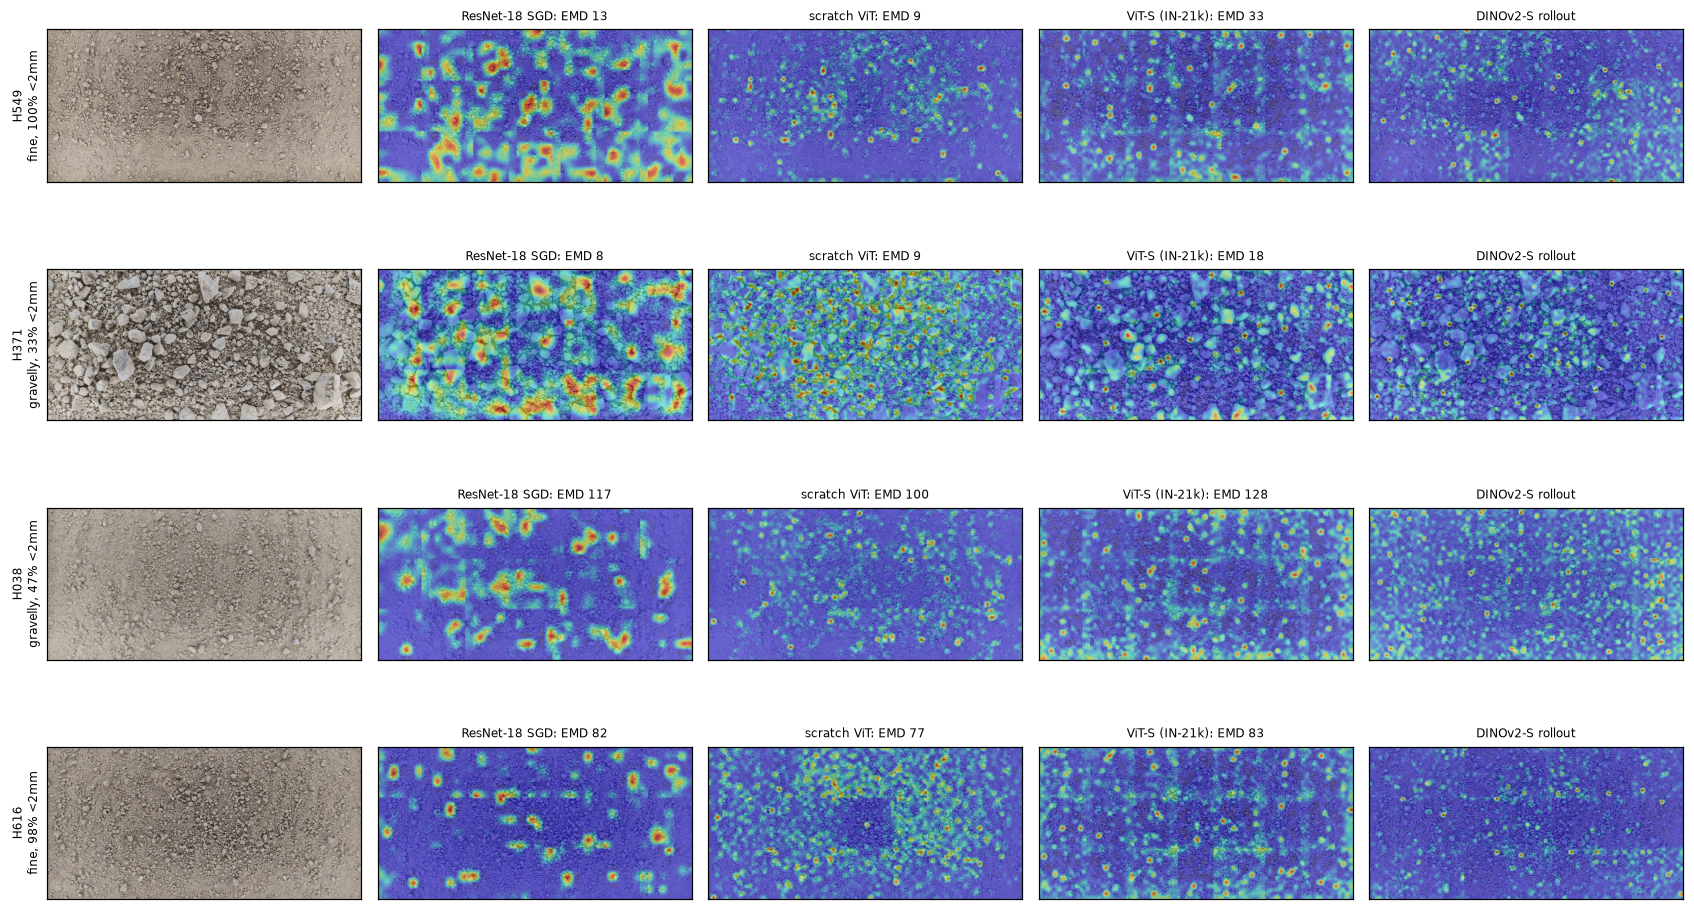

In [2]:
def dinov2_model():
    m = timm.create_model("vit_small_patch14_reg4_dinov2.lvd142m", pretrained=True, num_classes=11, img_size=224)
    cfg = {"img_size": 224, "tile_mm": 50}
    return m.to(device).eval(), cfg, m.pretrained_cfg["mean"], m.pretrained_cfg["std"]

oof = {k: pd.read_csv(paths.EXPERIMENTS / v / "oof.csv", index_col=0) for k, v in MODELS.items()}
show = ["H549", "H371", "H038", "H616"]
cols = ["photo"] + list(MODELS) + ["DINOv2-S frozen"]
fig, axes = plt.subplots(len(show), len(cols), figsize=(3.1 * len(cols), 2.3 * len(show)))
dino = dinov2_model()
for i, s in enumerate(show):
    k = int(fold_of[s])
    img = train_imgs[s][0]
    axes[i, 0].imshow(img); axes[i, 0].set_ylabel(f"{s}\n{group[s]}, {lab.loc[s, '2']:.0f}% <2mm", fontsize=8)
    for j, (title, name) in enumerate(MODELS.items(), start=1):
        model, cfg, mean, std = load_trained(name, k, device)
        method = "gradcam" if "r18" in name else "rollout"
        hm = photo_map(model, img, cfg, mean, std, device, method)
        axes[i, j].imshow(img); axes[i, j].imshow(hm, cmap="jet", alpha=.45)
        axes[i, j].set_title(f"{title}: EMD {oof[title].loc[s, 'emd']:.0f}", fontsize=8)
    hm = photo_map(dino[0], img, dino[1], dino[2], dino[3], device, "rollout")
    axes[i, -1].imshow(img); axes[i, -1].imshow(hm, cmap="jet", alpha=.45); axes[i, -1].set_title("DINOv2-S rollout", fontsize=8)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(paths.ROOT / "reports" / "fig_maps.png", dpi=110); plt.show()

## 2. Control experiments (numeric)
### C1 — colour alone (no model of grains at all)
Ridge on the six Lab colour statistics of each 50 mm tile, same folds and protocol as every model.

In [3]:
tiles = tile_feature_table(photos, 50)
colour_cols = ["L_mean", "a_mean", "b_mean", "L_std", "a_std", "b_std"]
c1 = {}
for name, cols_ in (("colour only (6 Lab stats)", colour_cols), ("texture only (DoG, 17)", [c for c in tiles.columns if "dog" in c]),
                    ("texture + colour (23)", colour_cols + [c for c in tiles.columns if "dog" in c])):
    o = ridge_tile_oof(tiles, labels, folds, alpha=10, feature_cols=cols_)
    _, pf = fold_scores(o, labels, folds)
    c1[name] = f"{pf.mean():.1f} ± {pf.std(ddof=0):.1f}"
display(pd.Series(c1, name="CV EMD").to_frame())

,CV EMD
colour only (6 Lab stats),43.8 ± 12.7
"texture only (DoG, 17)",41.8 ± 13.7
texture + colour (23),38.2 ± 14.6


### C2 — the same trained models on perturbed held-out tiles
* **mean colour**: every pixel of a tile replaced by the tile's mean colour (colour only, no texture);
* **greyscale**: colour removed, texture kept;
* **shuffle 4×4 / 8×8**: tile cut into 12.5 mm / 6 mm pieces and permuted (texture kept, layout and
  objects larger than a piece destroyed);
* **centre / border tiles**: prediction from tiles in the central half of the tray vs the rest.

In [4]:
variants = {"original": {}, "mean colour": {"tile_fn": mean_colour_only}, "greyscale": {"tile_fn": grayscale},
            "shuffle 4x4 (12.5 mm)": {"tile_fn": shuffle_patches(4)}, "shuffle 8x8 (6 mm)": {"tile_fn": shuffle_patches(8)},
            "centre tiles only": {"tiles_subset": centre_tiles(0.5)}, "border tiles only": {"tiles_subset": border_tiles(0.5)}}
rows, per_sample = [], {}
for title, name in MODELS.items():
    for k in sorted(fold_of.unique()):
        model, cfg, mean, std = load_trained(name, int(k), device)
        ids = fold_of.index[fold_of == k]
        for v, kw in variants.items():
            e = emd_of(sample_curves(model, {s: train_imgs[s] for s in ids}, cfg, mean, std, device, **kw), labels)
            per_sample.setdefault((title, v), []).append(e)
        del model; torch.cuda.empty_cache()
for (title, v), parts in per_sample.items():
    e = pd.concat(parts)
    rows.append({"model": title, "input": v, "EMD": e.mean(), "gravelly": e[group[e.index] == "gravelly"].mean(),
                 "fine": e[group[e.index] == "fine"].mean()})
ctrl = pd.DataFrame(rows)
table = ctrl.pivot(index="input", columns="model", values="EMD").loc[list(variants)]
display(table.round(1))
display((table - table.loc["original"]).round(1).rename(index=lambda i: f"Δ {i}"))
display(ctrl.pivot(index="input", columns="model", values="gravelly").loc[["original", "shuffle 4x4 (12.5 mm)", "shuffle 8x8 (6 mm)"]].round(1)
        .rename(columns=lambda c: f"{c} (gravelly)"))
ctrl.to_csv(paths.ROOT / "reports" / "controls_part4.csv", index=False)

model,ResNet-18 SGD,ViT-S (IN-21k),scratch ViT
input,,,
original,34.8,44.4,35.1
mean colour,91.9,103.0,96.5
greyscale,46.2,46.9,50.8
shuffle 4x4 (12.5 mm),35.6,43.8,35.5
shuffle 8x8 (6 mm),36.2,45.5,35.3
centre tiles only,34.4,43.2,36.6
border tiles only,34.9,44.6,34.9


model,ResNet-18 SGD,ViT-S (IN-21k),scratch ViT
input,,,
Δ original,0.0,0.0,0.0
Δ mean colour,57.1,58.6,61.4
Δ greyscale,11.4,2.5,15.7
Δ shuffle 4x4 (12.5 mm),0.8,-0.6,0.4
Δ shuffle 8x8 (6 mm),1.5,1.1,0.2
Δ centre tiles only,-0.3,-1.2,1.5
Δ border tiles only,0.1,0.3,-0.1


model,ResNet-18 SGD (gravelly),ViT-S (IN-21k) (gravelly),scratch ViT (gravelly)
input,,,
original,31.2,34.5,31.1
shuffle 4x4 (12.5 mm),31.0,35.1,31.0
shuffle 8x8 (6 mm),33.8,36.5,31.4


### C3 — device as a shortcut
Prediction = mean curve of the training samples photographed with the same phone (photo-level, then
averaged per sample), on the same folds.

In [5]:
ph = photos[photos.split == "train"]
pred = {}
for k in sorted(fold_of.unique()):
    tr_ph = ph[ph.sample_id.map(fold_of) != k]
    cam_curve = tr_ph.groupby("camera").sample_id.apply(lambda s: lab.loc[s, COLS].to_numpy(float).mean(0))
    for s in fold_of.index[fold_of == k]:
        overall = lab.loc[tr_ph.sample_id.unique(), COLS].to_numpy(float).mean(0)  # phone unseen in training
        pred[s] = np.mean([cam_curve[c] if c in cam_curve.index else overall for c in ph[ph.sample_id == s].camera], 0)
dev = pd.DataFrame(pred, index=COLS).T
_, pf = fold_scores(dev, labels, folds)
print(f"device-mean-curve predictor: CV {pf.mean():.1f} ± {pf.std(ddof=0):.1f}   (plain mean curve: 93.4)")

device-mean-curve predictor: CV 93.0 ± 10.0   (plain mean curve: 93.4)
